# Variazione di embedding di oggetti uguali ma su pose diverse

In [1]:
import sys
sys.path.append("/Experiments/riccardop02")
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1" 
os.environ["HF_HOME"] = "/Experiments/riccardop02/huggingface"

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor

from JEPA.Essential.path import RENDERS
import plotly.io as pio #; pio.renderers.default = "notebook"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

/Experiments/riccardop02/poseJepa/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


In [2]:
MODEL_NAME = "facebook/dinov2-base"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME, attn_implementation="eager").to(device).eval()

# spegniamo i gradienti: facciamo solo inferenza, encoder frozen
for p in model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", model.config.patch_size, "| hidden dim:", model.config.hidden_size)

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 972.07it/s] 


facebook/dinov2-base caricato — 86.6M parametri
patch size: 14 | hidden dim: 768


In [3]:
import torch
import torch.nn.functional as F
from PIL import Image

# --------------------------------------------------------------------------
# CACHE DEI FORWARD PASS
# --------------------------------------------------------------------------
_FORWARD_CACHE = {}   # (path, needs_attention) -> (hidden_states_cpu, attentions_cpu)

def clear_forward_cache():
    """Svuota la cache (utile tra un dataset e l'altro per liberare memoria)."""
    _FORWARD_CACHE.clear()

def _run_model(pil_img, need_attn):
    inputs = processor(images=pil_img, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs, output_hidden_states=True, output_attentions=need_attn)
    return outputs.hidden_states, outputs.attentions

@torch.no_grad()
def extract_features2(img, layers=[-1], token="pool", grid=2,
                     norm_mode="global", normalize=True,
                     use_cache=True, reduced_dim=32):
    
    needs_attention = (token in ["decimation", "weighted_pool"])

    if isinstance(img, str):
        cache_key = (img, needs_attention)
        if use_cache and cache_key in _FORWARD_CACHE:
            # 1. RIPESCHIAMO DALLA RAM (CPU) E RIPORTIAMO SU GPU
            hs_cpu, attn_cpu = _FORWARD_CACHE[cache_key]
            hs = tuple(h.to(device) for h in hs_cpu)
            
            if attn_cpu is not None:
                attn = tuple(
                    a.to(device) if isinstance(a, torch.Tensor) 
                    else tuple(x.to(device) for x in a) if isinstance(a, tuple)
                    else a 
                    for a in attn_cpu
                )
            else:
                attn = None
        else:
            pil_img = Image.open(img).convert("RGB")
            hs, attn = _run_model(pil_img, needs_attention)
            
            if use_cache:
                # 2. SPOSTIAMO TUTTO SULLA RAM (CPU) PRIMA DI SALVARE NELLA CACHE
                hs_cpu = tuple(h.cpu() for h in hs)
                
                if attn is not None:
                    attn_cpu = tuple(
                        a.cpu() if isinstance(a, torch.Tensor) 
                        else tuple(x.cpu() for x in a) if isinstance(a, tuple)
                        else a 
                        for a in attn
                    )
                else:
                    attn_cpu = None
                    
                _FORWARD_CACHE[cache_key] = (hs_cpu, attn_cpu)
    else:
        hs, attn = _run_model(img, needs_attention)

    if needs_attention:
        if not attn or attn[0] is None or len(attn[0]) == 0:
            raise RuntimeError("Attenzione mancante: ricarica il modello con attn_implementation='eager'")

    parts = []
    for L in layers:
        h = hs[L][0]

        if token == "cls":
            v = h[0]

        elif token == "PatchToken":
            v = h[1:]

        elif token == "ptc":
            v = h[1:].flatten()

        elif token == "pool":
            P = h[1:]
            side = int(P.shape[0] ** 0.5)
            g = P.reshape(side, side, -1)
            step = side // grid
            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell = g[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                    if norm_mode == "cell":
                        cell = F.normalize(cell, dim=-1)
                    cells.append(cell)
            v = torch.cat(cells)

        elif token == "decimation":
            attn_idx = (L - 1) if L > 0 else L
            attn_tensor = attn[attn_idx]
            if isinstance(attn_tensor, tuple): attn_tensor = attn_tensor[0]
            attn_layer = attn_tensor[0]

            mean_attn = attn_layer.mean(dim=0)
            cls_to_patch_attn = mean_attn[0, 1:]

            P = h[1:]
            side = int(P.shape[0] ** 0.5)
            grid_P = P.reshape(side, side, -1)
            grid_attn = cls_to_patch_attn.reshape(side, side)

            step = side // grid
            surviving_tokens = []
            for r in range(grid):
                for c in range(grid):
                    cell_tokens = grid_P[r*step:(r+1)*step, c*step:(c+1)*step, :]
                    cell_attn = grid_attn[r*step:(r+1)*step, c*step:(c+1)*step]

                    flat_idx = cell_attn.argmax()
                    max_r, max_c = divmod(flat_idx.item(), step)
                    best_token = cell_tokens[max_r, max_c, :]

                    if norm_mode == "cell":
                        best_token = F.normalize(best_token, dim=-1)
                    surviving_tokens.append(best_token)
            v = torch.stack(surviving_tokens).flatten()

        elif token == "weighted_pool":
            attn_idx = (L - 1) if L > 0 else L
            attn_tensor = attn[attn_idx]
            if isinstance(attn_tensor, tuple): attn_tensor = attn_tensor[0]
            attn_layer = attn_tensor[0]

            cls_to_patch_attn = attn_layer.mean(dim=0)[0, 1:]
            P = h[1:]
            side = int(P.shape[0] ** 0.5)
            grid_P = P.reshape(side, side, -1)
            grid_attn = cls_to_patch_attn.reshape(side, side)
            step = side // grid

            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell_tokens = grid_P[r*step:(r+1)*step, c*step:(c+1)*step, :]
                    cell_attn = grid_attn[r*step:(r+1)*step, c*step:(c+1)*step]

                    flat_tokens = cell_tokens.reshape(-1, 768)
                    flat_attn = cell_attn.reshape(-1)
                    weights = flat_attn / (flat_attn.sum() + 1e-8)
                    weighted_cell = (flat_tokens * weights.unsqueeze(-1)).sum(dim=0)

                    if norm_mode == "cell":
                        weighted_cell = F.normalize(weighted_cell, dim=-1)
                    cells.append(weighted_cell)
            v = torch.stack(cells).flatten()

        elif token == "hybrid":
            cls = F.normalize(h[0], dim=-1)
            P = h[1:]
            side = int(P.shape[0] ** 0.5)
            gr = P.reshape(side, side, -1)
            step = side // grid
            cells = [gr[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                     for r in range(grid) for c in range(grid)]
            pool = F.normalize(torch.cat(cells), dim=-1)
            v = torch.cat([cls, pool])

        elif token == "proj":
            if not hasattr(extract_features2, "proj_matrices"):
                extract_features2.proj_matrices = {}
            if reduced_dim not in extract_features2.proj_matrices:
                g = torch.Generator(device=device).manual_seed(42)
                extract_features2.proj_matrices[reduced_dim] = torch.randn(
                    reduced_dim, 768, generator=g, device=device) / (reduced_dim ** 0.5)
            proj_matrix = extract_features2.proj_matrices[reduced_dim]
            v = (h[1:] @ proj_matrix.T).flatten()
            if norm_mode == "cell":
                v = F.normalize(v, dim=-1)

        else:
            raise ValueError(token)

        exclude_from_global = ("hybrid",)
        if token in ["pool", "decimation", "weighted_pool", "proj"] and norm_mode == "cell":
            exclude_from_global += (token,)

        if normalize and token not in exclude_from_global:
            v = F.normalize(v, dim=-1)
        parts.append(v)

    return torch.cat(parts, dim=-1)

print("Extract Features Ready (GPU memory fix applicato!)")

Extract Features Ready (GPU memory fix applicato!)


In [6]:
# COMPUTE PCA
import pandas as pd

def PCA_MATRIX(dataset, K):
    TOKEN   = "PatchToken"

    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv").reset_index(drop=True)

    # Compute the representation for all the image generated from the script
    print(f"Calcolo embedding di {len(df)} immagini...")
    gallery = []
    for i in range(len(df)):
        e = extract_features2(Image.open(RENDERS / df.iloc[i]["image"]).convert("RGB"),
                            token=TOKEN)
        #print(f"{e.shape}")
        gallery.append(e)
    gallery = torch.stack(gallery)

    N, D, C = gallery.shape                  # (N, 256, 768)
    X = gallery.reshape(N * D, C).cpu().numpy()   # (N*256, 768)

    from sklearn.decomposition import PCA
    pca = PCA(n_components=K)
    pca.fit(X)

    return pca

pca_lmo = PCA_MATRIX(dataset = "lmo", K = 32)
pca_ycbv = PCA_MATRIX(dataset = "ycbv", K = 32)



Calcolo embedding di 800 immagini...
Calcolo embedding di 1912 immagini...


In [7]:
import torch
import torch.nn.functional as F

# --------------------------------------------------------------------------
# CUBIST MERGE (Gong & Lis, 2025) — adattamento single-shot
# Applicato UNA VOLTA sui patch token finali di DINOv2 (non iterativamente
# tra i layer come nel paper originale), per confrontarlo direttamente col
# tuo "pool" a parita' di dimensione di output (stesso parametro grid).
# --------------------------------------------------------------------------

def _bipartite_merge_1d(tokens, r):
    """
    Fonde r coppie di token adiacenti lungo una sequenza 1D (una riga o
    una colonna della griglia di patch), usando:
      - grafo a percorso: ogni sorgente vede solo i vicini immediati
      - matching bipartito: sorgenti = indici dispari, destinazioni = pari
      - rappresentazione finale = max-magnitude-per-dimensione (non media)

    tokens : (L, D)
    r      : numero di fusioni da eseguire (0 <= r <= L//2)
    return : (L - r, D), ordine spaziale originale preservato
    """
    L, D = tokens.shape
    if r <= 0:
        return tokens
    r = min(r, L // 2)

    dst_idx = torch.arange(0, L, 2, device=tokens.device)   # posizioni pari
    src_idx = torch.arange(1, L, 2, device=tokens.device)   # posizioni dispari
    dst, src = tokens[dst_idx], tokens[src_idx]
    n_dst, n_src = dst.shape[0], src.shape[0]

    dst_n, src_n = F.normalize(dst, dim=-1), F.normalize(src, dim=-1)

    # per ogni sorgente: similarita' coseno coi 1-2 vicini ammessi dal path graph
    best_sim = torch.full((n_src,), -2.0, device=tokens.device)
    best_dst = torch.full((n_src,), -1, dtype=torch.long, device=tokens.device)
    for j in range(n_src):
        cands = [j] if j + 1 >= n_dst else [j, j + 1]
        sims = torch.stack([torch.dot(src_n[j], dst_n[c]) for c in cands])
        k = int(sims.argmax())
        best_sim[j] = sims[k]
        best_dst[j] = cands[k]

    # top-r fusioni per similarita', ogni destinazione accetta una sola fusione
    order = torch.argsort(best_sim, descending=True).tolist()
    used_dst, pairs = set(), []
    for j in order:
        d = int(best_dst[j])
        if d in used_dst:
            continue
        pairs.append((j, d))
        used_dst.add(d)
        if len(pairs) == r:
            break

    merged_src = torch.zeros(n_src, dtype=torch.bool)
    new_dst = dst.clone()
    for j, d in pairs:
        merged_src[j] = True
        cand = torch.stack([new_dst[d], src[j]])          # (2, D)
        pick = cand.abs().argmax(dim=0)                    # max-magnitude-per-dim
        new_dst[d] = cand[pick, torch.arange(D, device=tokens.device)]

    kept_src, kept_src_idx = src[~merged_src], src_idx[~merged_src]
    out_idx = torch.cat([dst_idx, kept_src_idx])
    out_tok = torch.cat([new_dst, kept_src], dim=0)
    return out_tok[torch.argsort(out_idx)]


def _merge_1d_to_target(tokens, target_len):
    """Applica _bipartite_merge_1d ripetutamente finche' non si arriva a target_len."""
    cur = tokens
    while cur.shape[0] > target_len:
        r = min(cur.shape[0] // 2, cur.shape[0] - target_len)
        cur = _bipartite_merge_1d(cur, r)
    return cur


def cubist_merge_patches(P, target_grid):
    """
    P : (N_patch, D) patch token (es. 256 x 768 per DINOv2-base 224x224)
    target_grid : lato della griglia finale (es. 2 -> output 2x2 token),
                  stessa semantica del parametro "grid" usato in "pool".
    return : vettore flatten di dimensione target_grid**2 * D
             (identica shape del token "pool" con lo stesso grid!)
    """
    side = int(P.shape[0] ** 0.5)
    grid_P = P.reshape(side, side, -1)

    # 1. riduzione ORIZZONTALE: ogni riga -> target_grid colonne
    rows = [_merge_1d_to_target(grid_P[r], target_grid) for r in range(side)]
    stage1 = torch.stack(rows, dim=0)                 # (side, target_grid, D)

    # 2. riduzione VERTICALE: ogni colonna -> target_grid righe
    cols = [_merge_1d_to_target(stage1[:, c, :], target_grid) for c in range(target_grid)]
    final = torch.stack(cols, dim=1)                  # (target_grid, target_grid, D)

    return final.reshape(-1)

print("CubistMerge pronto (cubist_merge_patches).")


_extract_features2_original = extract_features2

def extract_features2(img, layers=[-1], token="pool", grid=2,
                       norm_mode="global", normalize=True,
                       use_cache=True, reduced_dim=32):

    if token == "PatchTokenPCA_Generic":
        # richiede che 'pca' sia già stata fittata (vedi blocco COMPUTE PCA sopra)
        feat = _extract_features2_original(img, layers=layers, token="PatchToken", grid=grid,
                                            norm_mode=norm_mode, normalize=normalize,
                                            use_cache=use_cache, reduced_dim=reduced_dim)
        D, C = feat.shape
        X_query = feat.cpu().numpy()                    
        X_query_reduced = pca_lmo.transform(X_query)
        return torch.tensor(X_query_reduced, dtype=torch.float32)   

    if token == "PatchTokenPCA_Specific":
        # richiede che 'pca' sia già stata fittata (vedi blocco COMPUTE PCA sopra)
        feat = _extract_features2_original(img, layers=layers, token="PatchToken", grid=grid,
                                            norm_mode=norm_mode, normalize=normalize,
                                            use_cache=use_cache, reduced_dim=reduced_dim)
        D, C = feat.shape
        X_query = feat.cpu().numpy()                    
        X_query_reduced = pca_ycbv.transform(X_query)
        return torch.tensor(X_query_reduced, dtype=torch.float32)   


    if token != "cubist":
        return _extract_features2_original(img, layers=layers, token=token, grid=grid,
                                            norm_mode=norm_mode, normalize=normalize,
                                            use_cache=use_cache, reduced_dim=reduced_dim)

    # --- ramo CUBIST MERGE (invariato) ---
    if isinstance(img, str):
        cache_key = (img, False)
        if use_cache and cache_key in _FORWARD_CACHE:
            hs, attn = _FORWARD_CACHE[cache_key]
        else:
            pil_img = Image.open(img).convert("RGB")
            hs, attn = _run_model(pil_img, False)
            if use_cache:
                _FORWARD_CACHE[cache_key] = (hs, attn)
    else:
        hs, attn = _run_model(img, False)

    parts = []
    for L in layers:
        h = hs[L][0]
        P = h[1:]
        v = cubist_merge_patches(P, target_grid=grid)
        if normalize:
            v = F.normalize(v, dim=-1)
        parts.append(v)
    return torch.cat(parts, dim=-1)

CubistMerge pronto (cubist_merge_patches).


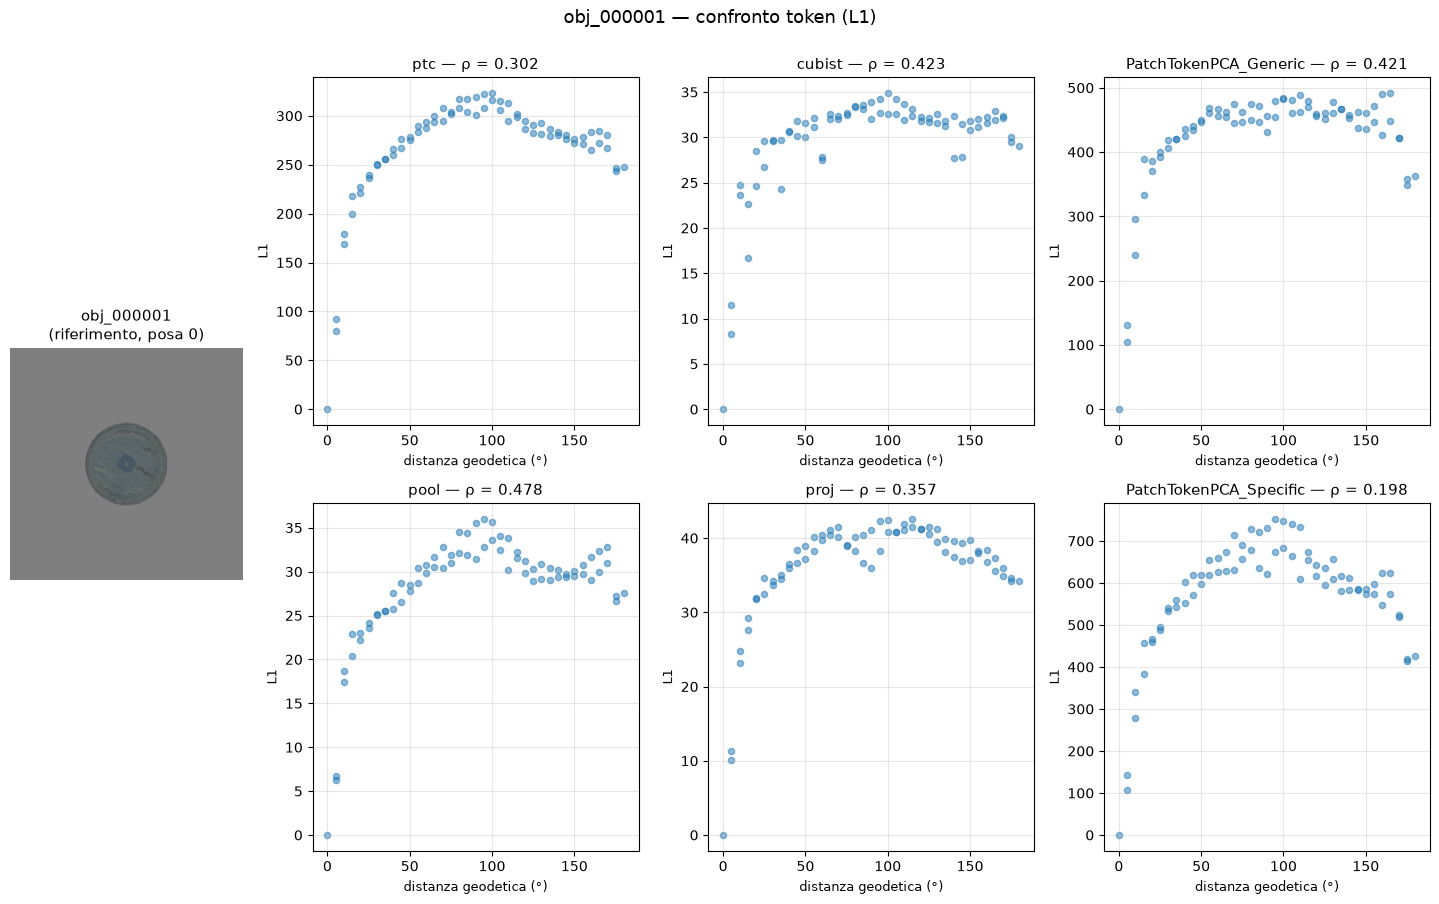

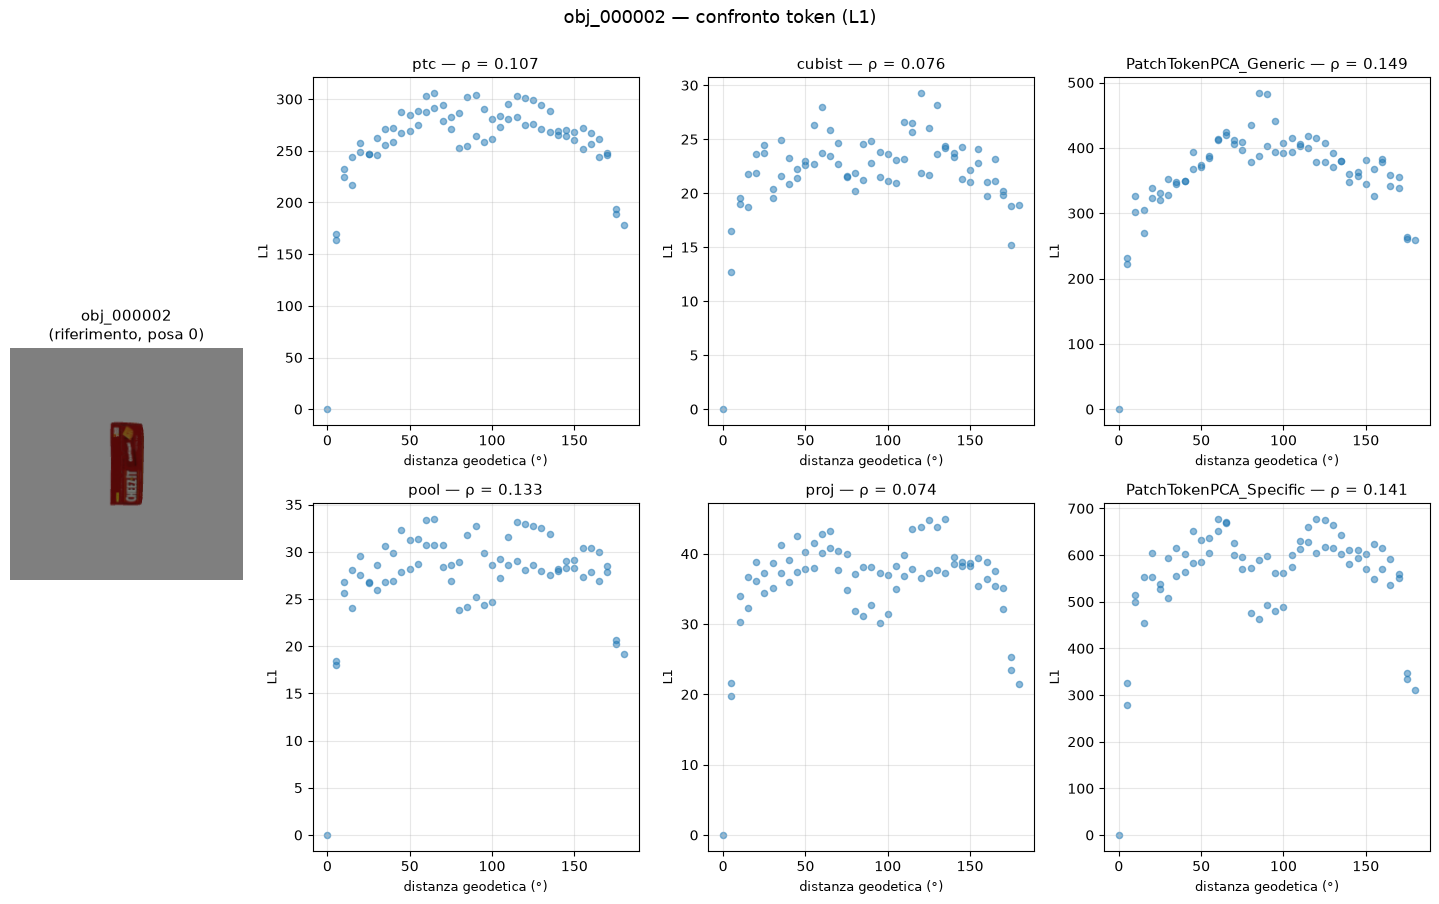

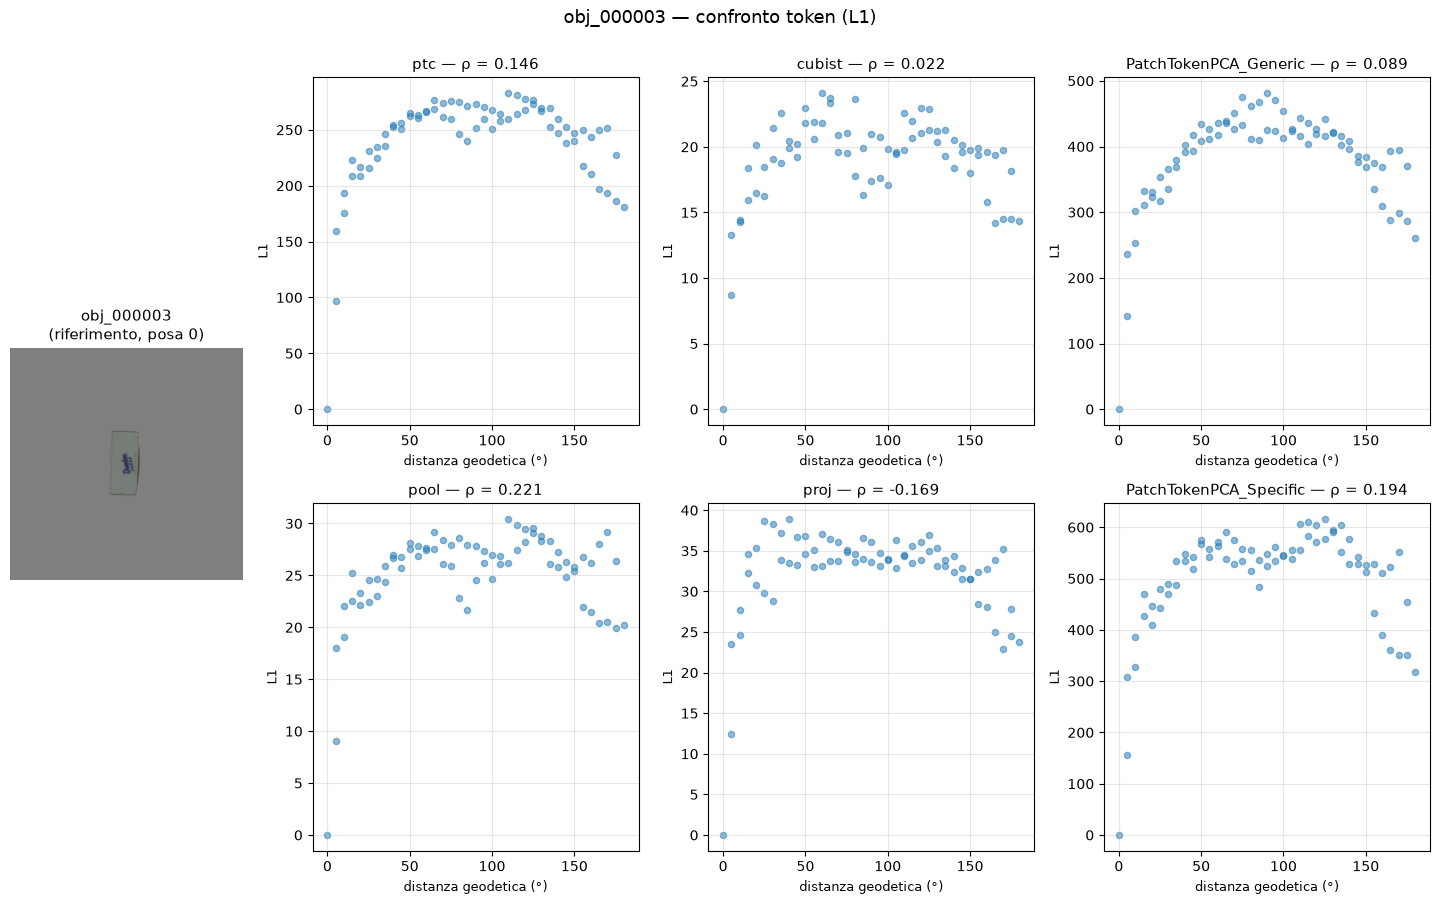

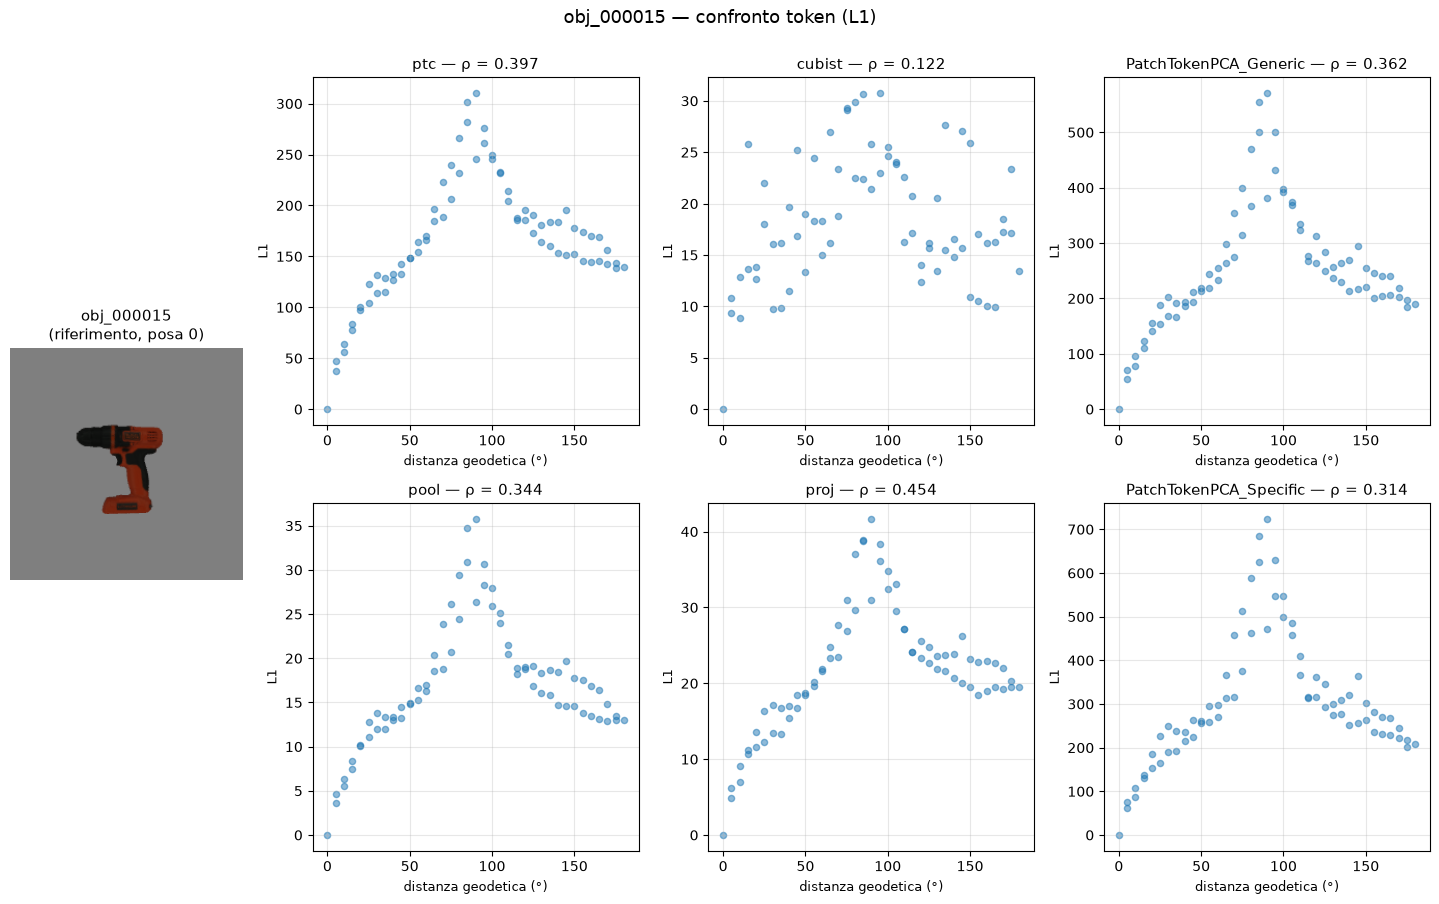

In [8]:
import pandas as pd
import math
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object_compare(obj_name, dataset="ycbv", layers=[-1], metric="L1",
                         tokens=("ptc", "pool", "cubist", "proj", "PatchTokenPCA_Generic", "PatchTokenPCA_Specific"),
                         grid=2, reduced_dim=12, ref_idx=0):
    """
    Come plot_object, ma calcola angolo-vs-distanza per PIU' token sullo
    stesso oggetto e li mostra affiancati (griglia dinamica), uno scatter con
    Spearman rho per ciascuno. A sinistra mostra anche l'immagine
    dell'oggetto di riferimento (posa ref_idx) per contesto visivo.
    """
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))
    R_ref = R_all[ref_idx]

    # angoli identici per tutti i token (dipendono solo dalla posa, non dall'embedding)
    angles = np.array([(R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
                        for i in range(len(df))])

    img_paths = [str(RENDERS / p) for p in df["image"]]   # str -> beneficia della cache

    # --- layout dinamico: immagine a sinistra, N scatter a destra (2 righe) ---
    n_tokens = len(tokens)
    n_cols_scatter = math.ceil(n_tokens / 2)   # 2 righe, tante colonne quante servono
    n_cols_total = n_cols_scatter + 1          # +1 per la colonna immagine

    fig = plt.figure(figsize=(4 + 3.5 * n_cols_scatter, 9))
    gs = fig.add_gridspec(2, n_cols_total, width_ratios=[1] + [1.4] * n_cols_scatter)

    ax_img = fig.add_subplot(gs[:, 0])
    ax_img.imshow(Image.open(img_paths[ref_idx]).convert("RGB"))
    ax_img.set_title(f"{obj_name}\n(riferimento, posa {ref_idx})", fontsize=11)
    ax_img.axis("off")

    scatter_positions = [gs[r, c] for c in range(1, n_cols_total) for r in range(2)]

    for pos, token in zip(scatter_positions, tokens):
        ax = fig.add_subplot(pos)

        kwargs = {}
        if token in ("pool", "cubist", "PatchTokenPCA_Generic", "PatchTokenPCA_Specific"):
            kwargs["grid"] = grid
        if token == "proj":
            kwargs["reduced_dim"] = reduced_dim

        def get_flat_embedding(img_path):
            e = extract_features2(img_path, layers=layers, token=token, **kwargs)
            e = e.reshape(-1)
            if e.is_cuda:
                e = e.cpu()
            return e

        e_ref = get_flat_embedding(img_paths[ref_idx])

        dists = []
        for i in range(len(df)):
            e = get_flat_embedding(img_paths[i])
            if metric == "cos_dist":
                d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
            elif metric == "L2":
                d = torch.norm(e_ref - e).item()
            elif metric == "L1":
                d = torch.abs(e_ref - e).sum().item()
            else:
                raise ValueError(metric)
            dists.append(d)
        dists = np.array(dists)

        rho, _ = spearmanr(angles, dists)
        ax.scatter(angles, dists, s=20, alpha=0.5)
        ax.set_xlabel("distanza geodetica (°)", fontsize=9)
        ax.set_ylabel(f"{metric}", fontsize=9)
        ax.set_title(f"{token} — ρ = {rho:.3f}", fontsize=11)
        ax.grid(alpha=0.3)

    plt.suptitle(f"{obj_name} — confronto token ({metric})", y=1.00, fontsize=13)
    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object_compare(obj, metric="L1")

# PROVA CON TRANSLAZIONI


Cosa cambia invece sulla translazione tra patch e class token????

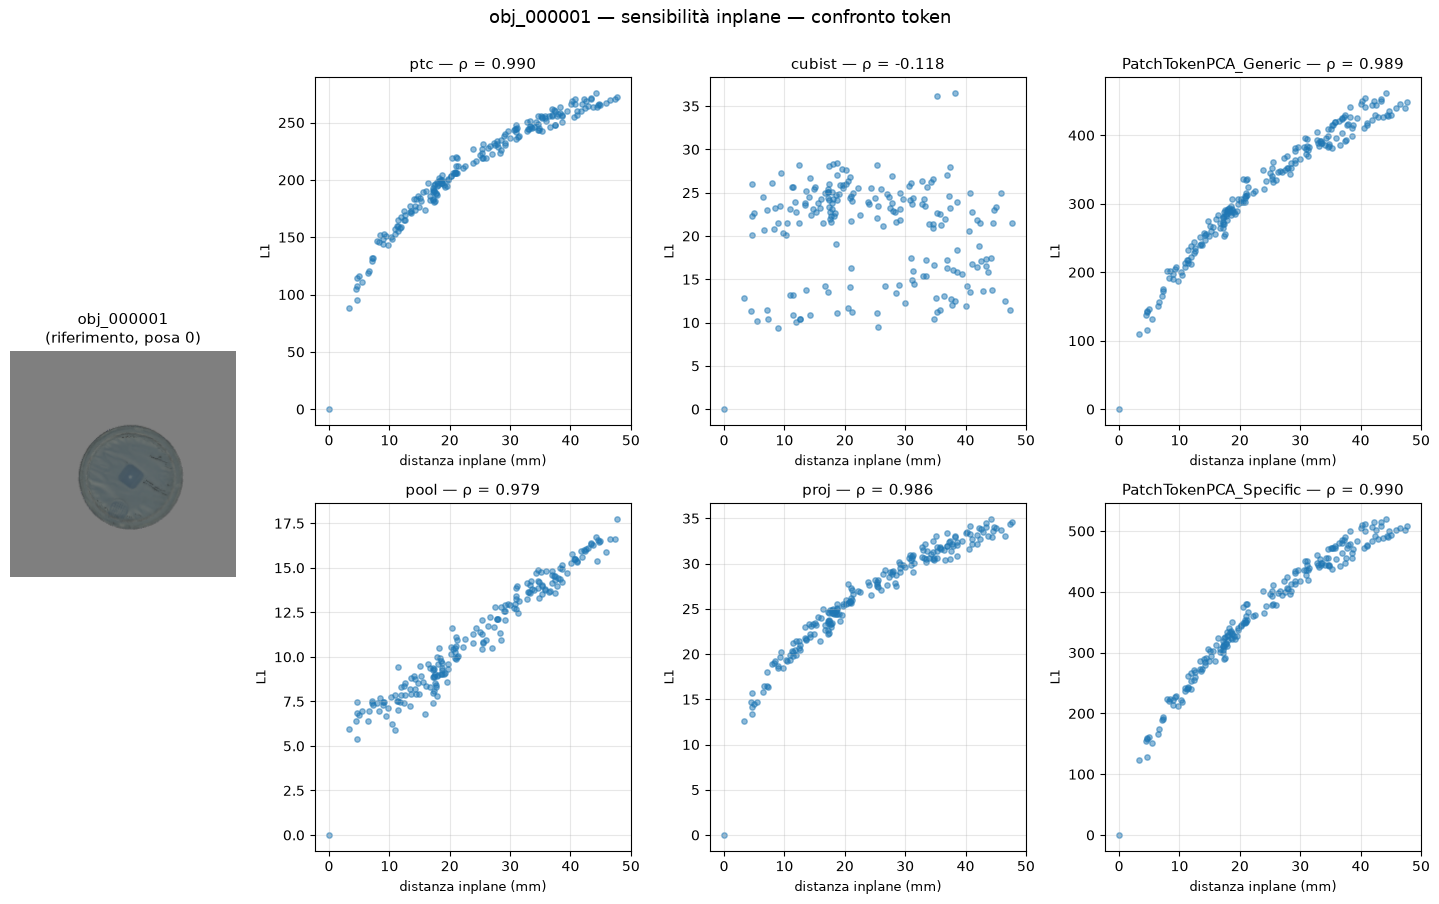

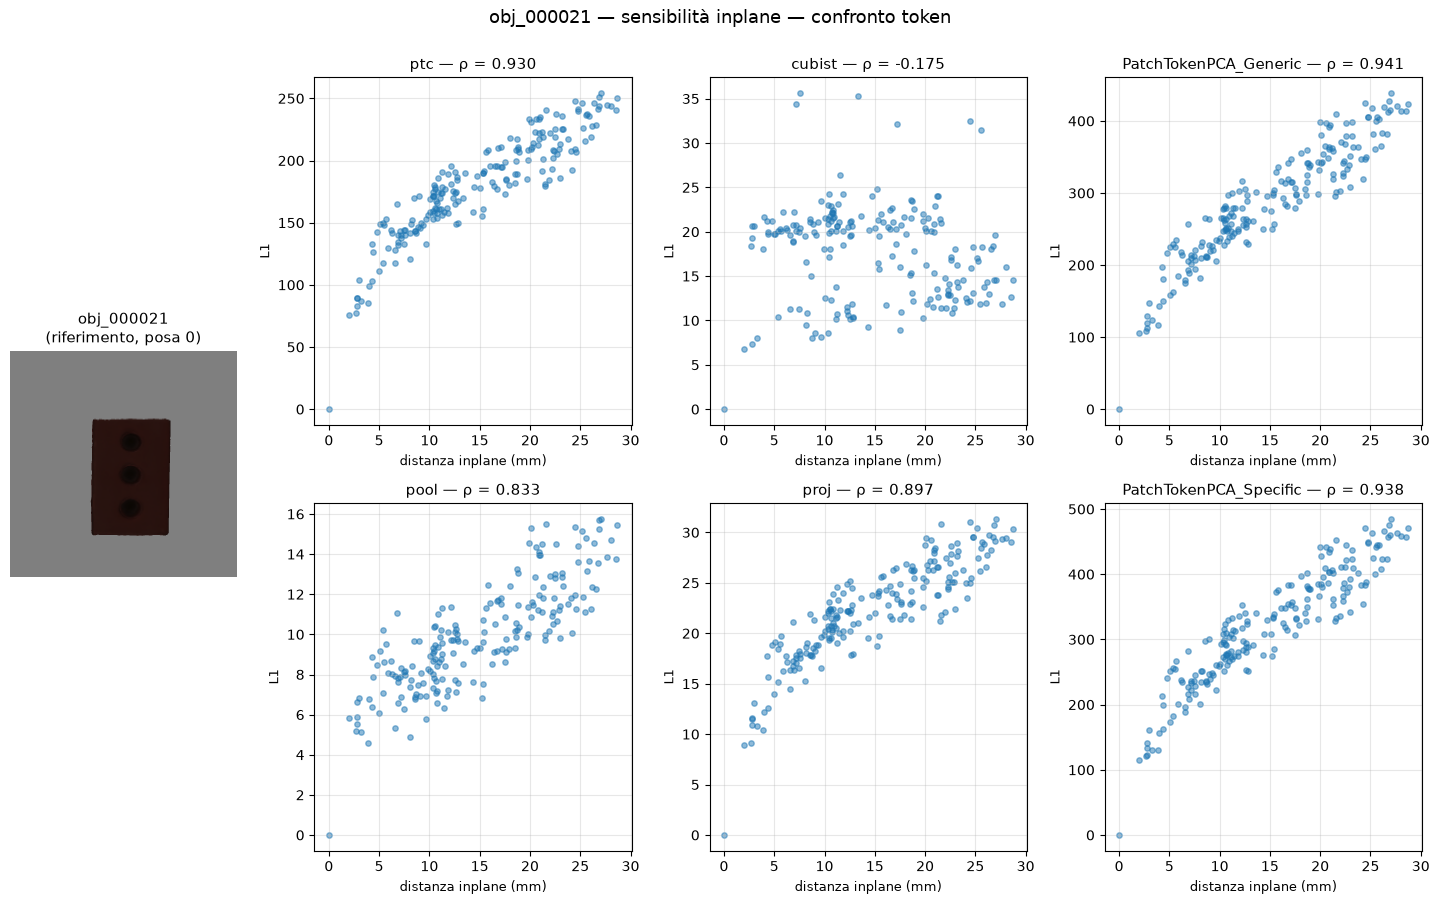

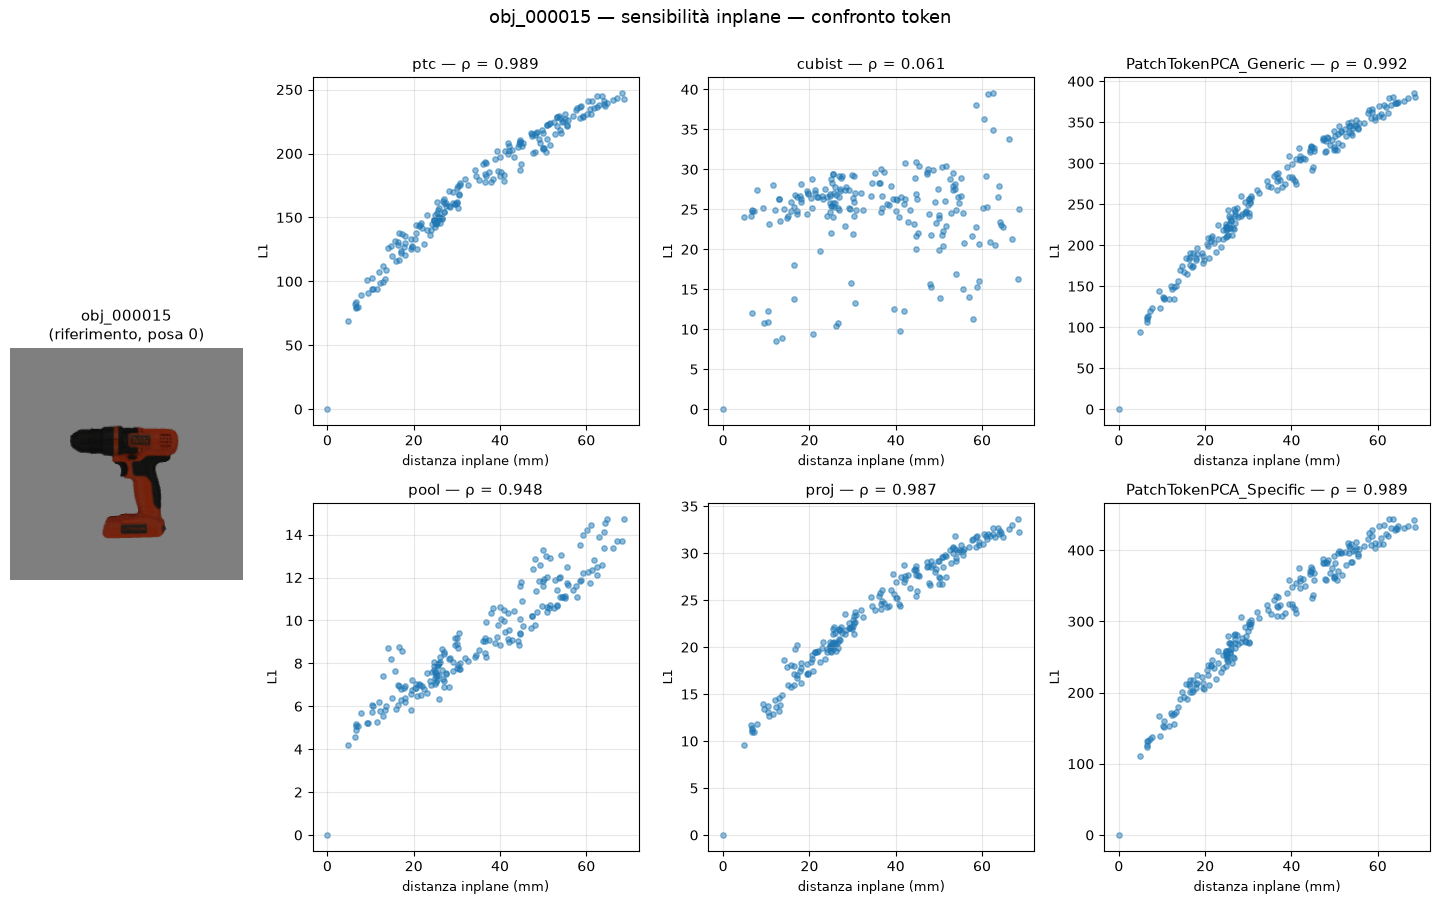

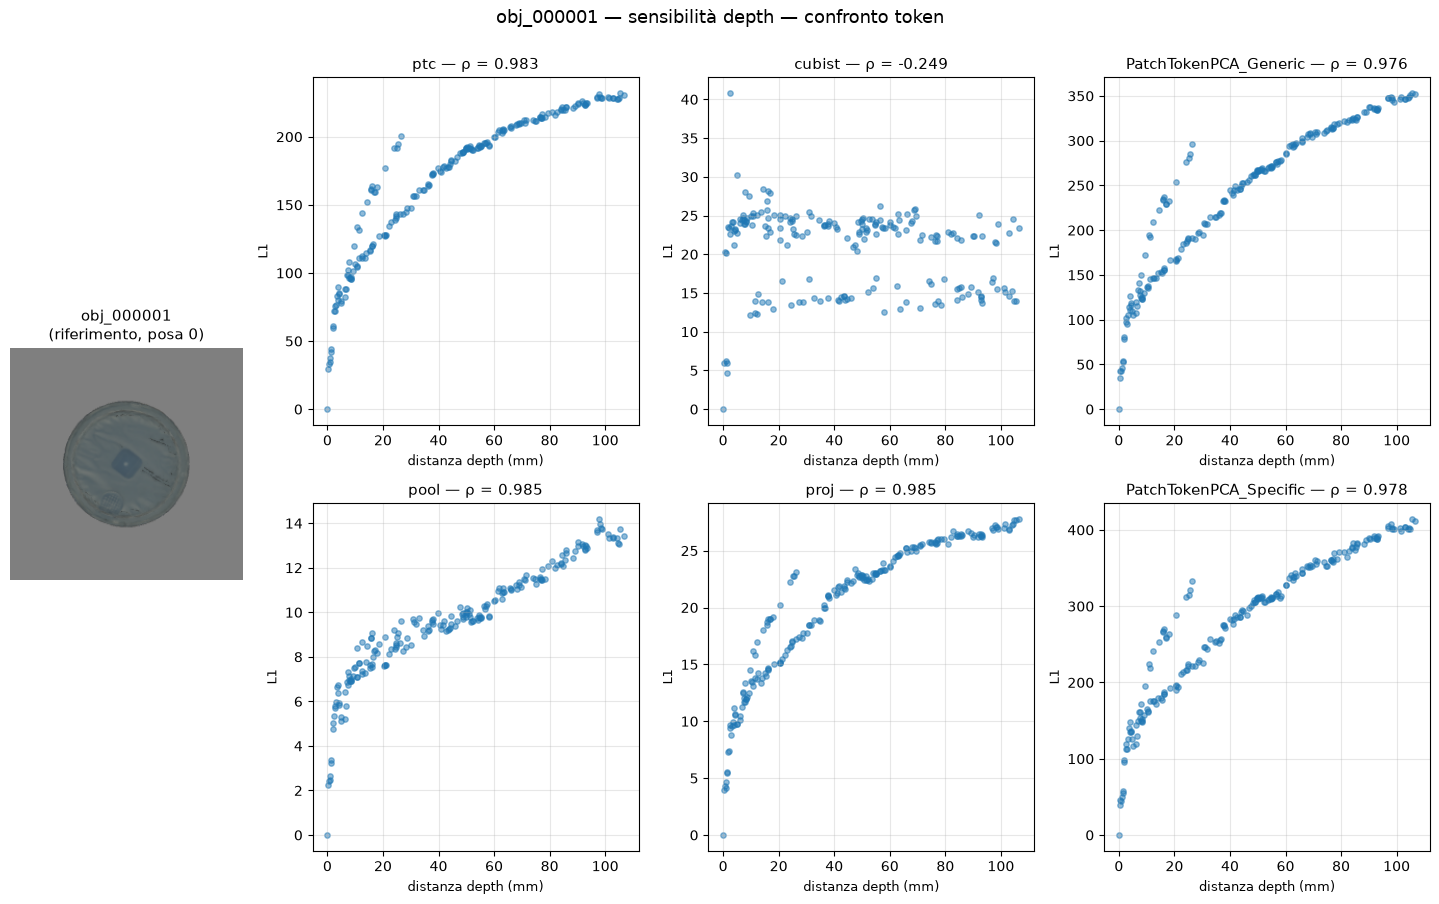

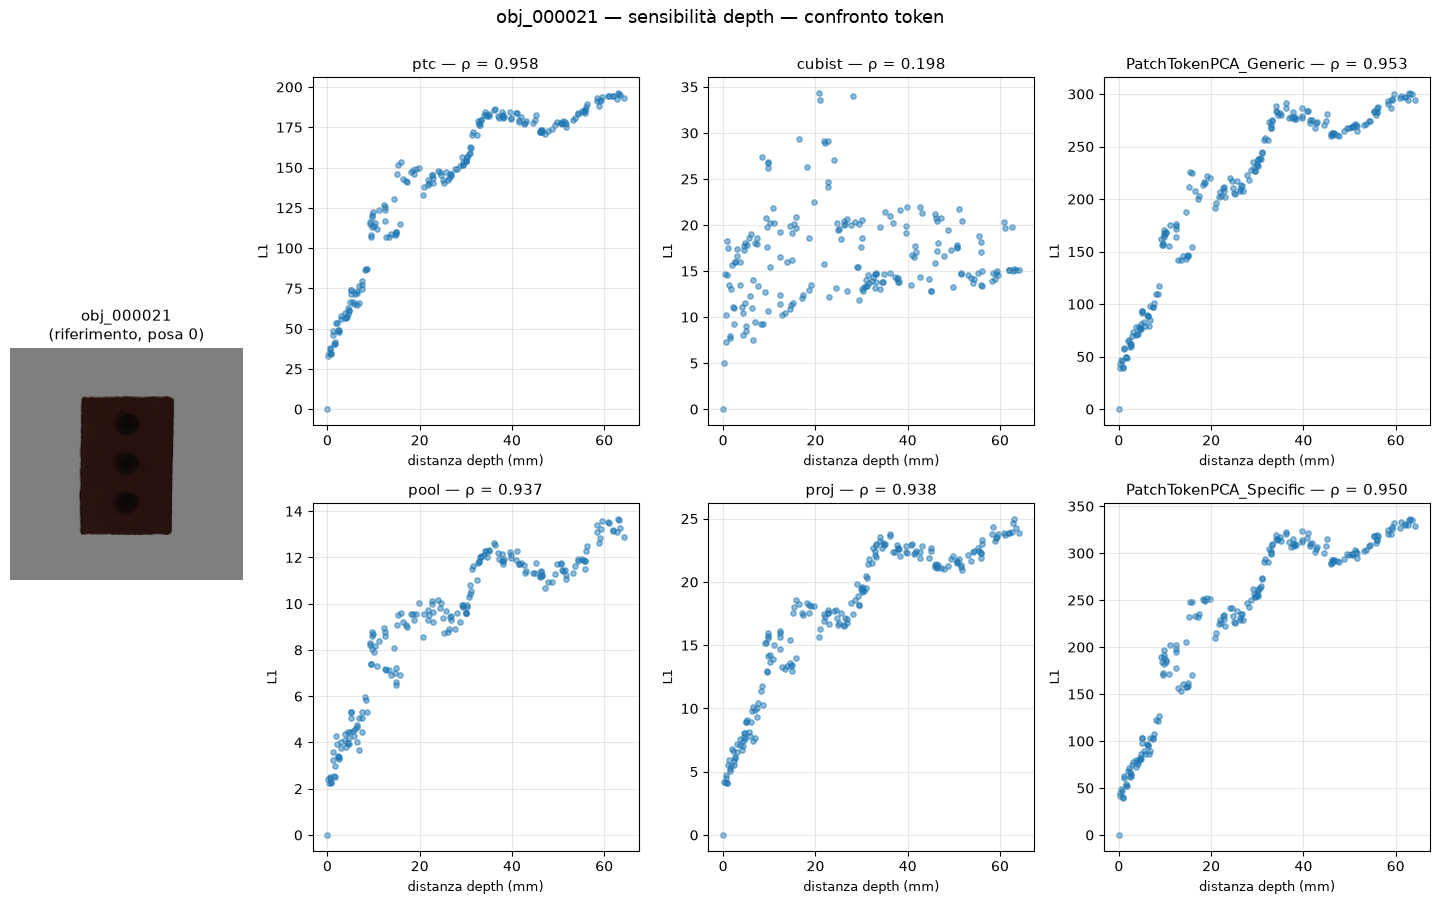

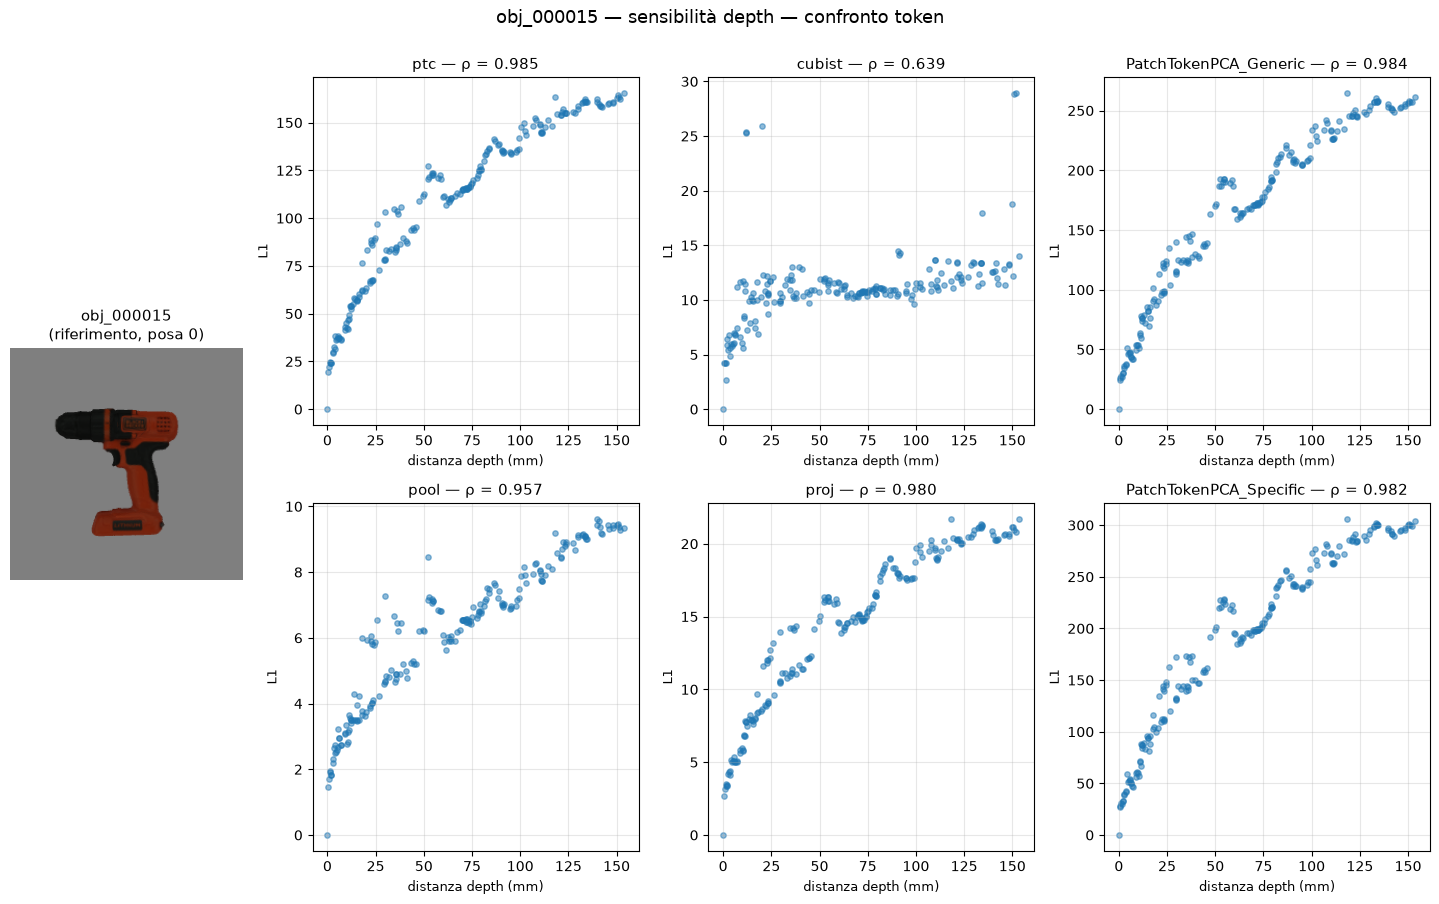

In [9]:
import pandas as pd
import math
from scipy.stats import spearmanr

def _sensitivity_trans_generic(obj_name, dataset, token, component, ref_idx=0, **kwargs):
    """
    Come sensitivity_trans originale, ma accetta **kwargs generici (grid per
    pool/cubist/PatchTokenPCA, reduced_dim per proj) cosi' da poter essere
    richiamata per qualsiasi token senza if/else espliciti.
    """
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)

    T_all = df[["tx", "ty", "tz"]].values
    t_ref = T_all[ref_idx]

    img_paths = [str(RENDERS / p) for p in df["image"]]   # str -> beneficia della cache

    def get_flat_embedding(img_path):
        e = extract_features2(img_path, token=token, **kwargs)
        e = e.reshape(-1)
        if e.is_cuda:
            e = e.cpu()
        return e

    e_ref = get_flat_embedding(img_paths[ref_idx])

    tdist, dists = [], []
    for i in range(len(df)):
        dt = T_all[i] - t_ref
        if component == "inplane":
            x = np.linalg.norm(dt[:2])
        elif component == "depth":
            x = abs(dt[2])
        else:
            x = np.linalg.norm(dt)
        tdist.append(x)

        e = get_flat_embedding(img_paths[i])
        dists.append(torch.abs(e_ref - e).sum().item())

    return np.array(tdist), np.array(dists), img_paths[ref_idx]


def plot_trans_compare(obj_name, dataset="ycbv_translation", component="all",
                        tokens=("ptc", "pool", "cubist", "proj", "PatchTokenPCA_Generic", "PatchTokenPCA_Specific"),
                        grid=2, reduced_dim=12, ref_idx=0):
    """
    Come plot_trans_objects, ma per UN oggetto confronta i token affiancati
    (griglia dinamica), con l'immagine dell'oggetto di riferimento a sinistra.
    """
    n_tokens = len(tokens)
    n_cols_scatter = math.ceil(n_tokens / 2)
    n_cols_total = n_cols_scatter + 1

    fig = plt.figure(figsize=(4 + 3.5 * n_cols_scatter, 9))
    gs = fig.add_gridspec(2, n_cols_total, width_ratios=[1] + [1.4] * n_cols_scatter)

    scatter_positions = [gs[r, c] for c in range(1, n_cols_total) for r in range(2)]

    ref_img_path = None
    for pos, token in zip(scatter_positions, tokens):
        ax = fig.add_subplot(pos)

        kwargs = {}
        if token in ("pool", "cubist", "PatchTokenPCA_Generic", "PatchTokenPCA_Specific"):
            kwargs["grid"] = grid
        if token == "proj":
            kwargs["reduced_dim"] = reduced_dim

        td, d, ref_img_path = _sensitivity_trans_generic(
            obj_name, dataset=dataset, token=token, component=component,
            ref_idx=ref_idx, **kwargs)

        rho = spearmanr(td, d).statistic
        ax.scatter(td, d, s=15, alpha=0.5)
        ax.set_title(f"{token} — ρ = {rho:.3f}", fontsize=11)
        ax.set_xlabel(f"distanza {component} (mm)", fontsize=9)
        ax.set_ylabel("L1", fontsize=9)
        ax.grid(alpha=0.3)

    ax_img = fig.add_subplot(gs[:, 0])
    ax_img.imshow(Image.open(ref_img_path).convert("RGB"))
    ax_img.set_title(f"{obj_name}\n(riferimento, posa {ref_idx})", fontsize=11)
    ax_img.axis("off")

    plt.suptitle(f"{obj_name} — sensibilità {component} — confronto token", y=1.00, fontsize=13)
    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000001", "obj_000021", "obj_000015"]
for obj in OBJECTS:
    plot_trans_compare(obj, dataset="ycbv_inplane", component="inplane", grid=2)
for obj in OBJECTS:
    plot_trans_compare(obj, dataset="ycbv_offplane", component="depth", grid=2)

# éPRPVA    

In [7]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def pose_sensitivity_rho(obj_name, dataset="ycbv", token="pool", metric="L1",
                          grid=2, layers=[-1], ref_idx=0, reduced_dim=32,
                          use_cache=True):
    """Versione 'headless' di plot_object: ritorna solo rho, nessun plot.
       Passa i path come stringa (non PIL.Image) per beneficiare della cache."""
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    if len(df) < 5:
        return np.nan   # troppe poche pose per questo oggetto, saltalo

    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))
    R_ref = R_all[ref_idx]

    ref_path = str(RENDERS / df.loc[ref_idx, "image"])
    e_ref = extract_features2(ref_path, layers=layers, token=token, grid=grid,
                              reduced_dim=reduced_dim, use_cache=use_cache)

    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        img_path = str(RENDERS / df.loc[i, "image"])
        e = extract_features2(img_path, layers=layers, token=token, grid=grid,
                              reduced_dim=reduced_dim, use_cache=use_cache)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d); angles.append(ang)

    rho, _ = spearmanr(np.array(angles), np.array(dists))
    return rho

print("pose_sensitivity_rho pronta.")

pose_sensitivity_rho pronta.


In [8]:
from itertools import product
import time

DATASET = "ycbv"
METRIC = "L1"
GRID = 2          # per "pool"
LAYERS = [-1]
REDUCED_DIM = 32  # per "proj"

TOKENS_TO_COMPARE = ["pool", "proj", "ptc"]

all_objs_df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
ALL_OBJECTS = sorted(all_objs_df["object"].unique())
print(f"{len(ALL_OBJECTS)} oggetti trovati in {DATASET}: {ALL_OBJECTS}")

records = []
t0 = time.time()
for obj in ALL_OBJECTS:
    clear_forward_cache()   # <-- svuota PRIMA di ogni oggetto: la cache resta piccola
    for token in TOKENS_TO_COMPARE:
        rho = pose_sensitivity_rho(obj, dataset=DATASET, token=token, metric=METRIC,
                                   grid=GRID, layers=LAYERS, reduced_dim=REDUCED_DIM)
        records.append({"object": obj, "token": token, "rho": rho})
        print(f"{obj:15s} | {token:6s} | rho = {rho:.3f}")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"\nCompletato in {time.time()-t0:.1f}s")
results_df = pd.DataFrame(records)

21 oggetti trovati in ycbv: ['obj_000001', 'obj_000002', 'obj_000003', 'obj_000004', 'obj_000005', 'obj_000006', 'obj_000007', 'obj_000008', 'obj_000009', 'obj_000010', 'obj_000011', 'obj_000012', 'obj_000013', 'obj_000014', 'obj_000015', 'obj_000016', 'obj_000017', 'obj_000018', 'obj_000019', 'obj_000020', 'obj_000021']
obj_000001      | pool   | rho = 0.478
obj_000001      | proj   | rho = 0.320
obj_000001      | ptc    | rho = 0.302
obj_000002      | pool   | rho = 0.133
obj_000002      | proj   | rho = 0.163
obj_000002      | ptc    | rho = 0.107
obj_000003      | pool   | rho = 0.221
obj_000003      | proj   | rho = 0.080
obj_000003      | ptc    | rho = 0.146
obj_000004      | pool   | rho = 0.365
obj_000004      | proj   | rho = 0.235
obj_000004      | ptc    | rho = 0.275
obj_000005      | pool   | rho = 0.492
obj_000005      | proj   | rho = 0.403
obj_000005      | ptc    | rho = 0.315
obj_000006      | pool   | rho = 0.151
obj_000006      | proj   | rho = 0.137
obj_000006    

In [9]:
from scipy import stats
from scipy.stats import wilcoxon

def summarize(df, group_col="token", value_col="rho", ci=0.95):
    out = []
    for name, g in df.groupby(group_col):
        vals = g[value_col].dropna().values
        n = len(vals)
        mean = vals.mean()
        if n > 1:
            sem = stats.sem(vals)
            h = sem * stats.t.ppf((1 + ci) / 2, n - 1)
            std = vals.std(ddof=1)
        else:
            h, std = np.nan, np.nan
        out.append({group_col: name, "n": n, "mean_rho": mean, "std_rho": std,
                    "ci95_low": mean - h, "ci95_high": mean + h})
    return pd.DataFrame(out).sort_values("mean_rho", ascending=False).reset_index(drop=True)

summary = summarize(results_df)
print(summary.to_string(index=False))

# --- test appaiato tra i metodi (stessi oggetti, metodi diversi -> Wilcoxon) ---
print("\n--- Test appaiato (Wilcoxon signed-rank) ---")
pivot = results_df.pivot(index="object", columns="token", values="rho").dropna()
for a, b in [("pool","proj"), ("pool","ptc"), ("proj","ptc")]:
    if a in pivot.columns and b in pivot.columns:
        stat, p = wilcoxon(pivot[a], pivot[b])
        diff = (pivot[a] - pivot[b]).mean()
        print(f"{a:6s} vs {b:6s} | diff medio rho = {diff:+.4f} | p-value = {p:.4f} | n={len(pivot)}"
              + ("  <-- significativo (p<0.05)" if p < 0.05 else ""))

token  n  mean_rho  std_rho  ci95_low  ci95_high
  ptc 21  0.332609 0.233511  0.226316   0.438902
 pool 21  0.332270 0.224975  0.229863   0.434678
 proj 21  0.320357 0.252529  0.205407   0.435307

--- Test appaiato (Wilcoxon signed-rank) ---
pool   vs proj   | diff medio rho = +0.0119 | p-value = 0.6827 | n=21
pool   vs ptc    | diff medio rho = -0.0003 | p-value = 0.8917 | n=21
proj   vs ptc    | diff medio rho = -0.0123 | p-value = 0.5854 | n=21


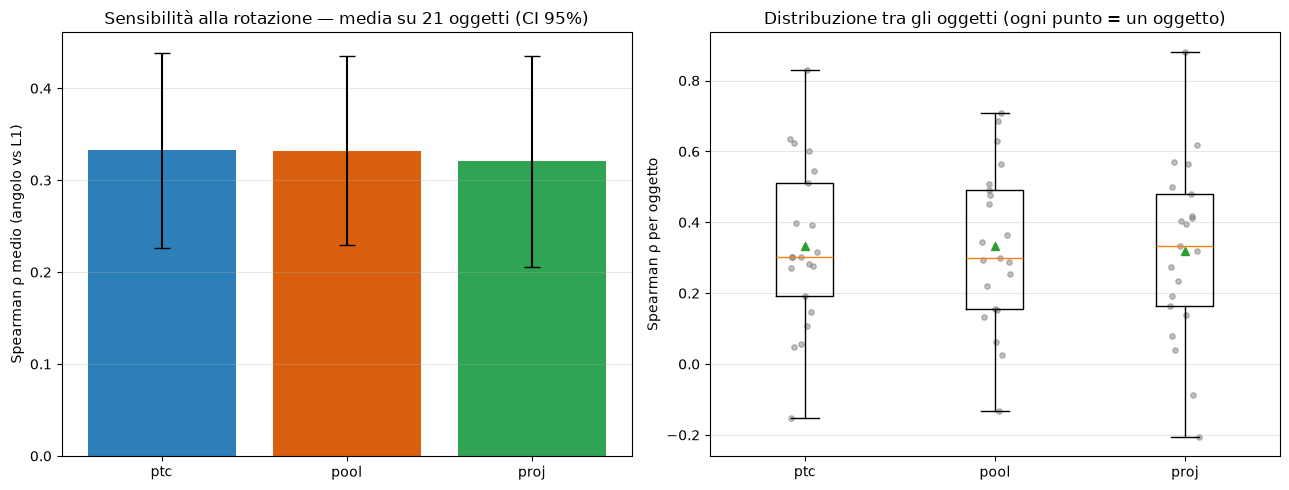

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- barplot con CI 95% ---
order = summary["token"].tolist()
means = summary.set_index("token").loc[order, "mean_rho"]
los = summary.set_index("token").loc[order, "ci95_low"]
his = summary.set_index("token").loc[order, "ci95_high"]
yerr = np.vstack([means - los, his - means])

axes[0].bar(order, means, yerr=yerr, capsize=6,
           color=["#2c7fb8", "#d95f0e", "#31a354"][:len(order)])
axes[0].set_ylabel("Spearman ρ medio (angolo vs L1)")
axes[0].set_title(f"Sensibilità alla rotazione — media su {len(ALL_OBJECTS)} oggetti (CI 95%)")
axes[0].grid(alpha=0.3, axis="y")

# --- distribuzione per oggetto ---
data_by_token = [results_df[results_df.token == t]["rho"].dropna().values for t in order]
axes[1].boxplot(data_by_token, tick_labels=order, showmeans=True)
for i, d in enumerate(data_by_token):
    axes[1].scatter(np.full(len(d), i+1) + np.random.uniform(-0.08, 0.08, len(d)),
                    d, alpha=0.5, s=15, color="gray")
axes[1].set_ylabel("Spearman ρ per oggetto")
axes[1].set_title("Distribuzione tra gli oggetti (ogni punto = un oggetto)")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

2

In [11]:
TARGET_DIM = 3072   # = grid 2x2 * 768, il default storico di "pool"
N_PATCHES = 256     # 16x16 patch per DINOv2-base a 224x224

grid_matched = max(1, round((TARGET_DIM / 768) ** 0.5))
reduced_dim_matched = max(1, round(TARGET_DIM / N_PATCHES))

print(f"Target dim ~{TARGET_DIM}")
print(f"  pool -> grid={grid_matched} ({grid_matched**2 * 768} dim)")
print(f"  proj -> reduced_dim={reduced_dim_matched} ({N_PATCHES * reduced_dim_matched} dim)")

clear_forward_cache()

records_matched = []
for obj in ALL_OBJECTS:
    rho_pool = pose_sensitivity_rho(obj, dataset=DATASET, token="pool", metric=METRIC,
                                    grid=grid_matched, layers=LAYERS)
    rho_proj = pose_sensitivity_rho(obj, dataset=DATASET, token="proj", metric=METRIC,
                                    reduced_dim=reduced_dim_matched, layers=LAYERS)
    records_matched.append({"object": obj, "token": "pool", "rho": rho_pool})
    records_matched.append({"object": obj, "token": "proj", "rho": rho_proj})
    print(f"{obj:15s} | pool(g={grid_matched}) = {rho_pool:.3f} | proj(d={reduced_dim_matched}) = {rho_proj:.3f}")

matched_df = pd.DataFrame(records_matched)
summary_matched = summarize(matched_df)
print("\n" + summary_matched.to_string(index=False))

pivot_m = matched_df.pivot(index="object", columns="token", values="rho").dropna()
stat, p = wilcoxon(pivot_m["pool"], pivot_m["proj"])
print(f"\npool vs proj (stessa dim ~{TARGET_DIM}) | p-value = {p:.4f}"
      + ("  <-- significativo" if p < 0.05 else "  (nessuna differenza significativa)"))

Target dim ~3072
  pool -> grid=2 (3072 dim)
  proj -> reduced_dim=12 (3072 dim)
obj_000001      | pool(g=2) = 0.478 | proj(d=12) = 0.357
obj_000002      | pool(g=2) = 0.133 | proj(d=12) = 0.074
obj_000003      | pool(g=2) = 0.221 | proj(d=12) = -0.169
obj_000004      | pool(g=2) = 0.365 | proj(d=12) = 0.188
obj_000005      | pool(g=2) = 0.492 | proj(d=12) = 0.459
obj_000006      | pool(g=2) = 0.151 | proj(d=12) = 0.164
obj_000007      | pool(g=2) = 0.564 | proj(d=12) = 0.668
obj_000008      | pool(g=2) = 0.630 | proj(d=12) = 0.683
obj_000009      | pool(g=2) = 0.287 | proj(d=12) = 0.326
obj_000010      | pool(g=2) = 0.709 | proj(d=12) = 0.815
obj_000011      | pool(g=2) = 0.293 | proj(d=12) = 0.188
obj_000012      | pool(g=2) = 0.064 | proj(d=12) = 0.044
obj_000013      | pool(g=2) = 0.299 | proj(d=12) = 0.406
obj_000014      | pool(g=2) = 0.508 | proj(d=12) = 0.746
obj_000015      | pool(g=2) = 0.344 | proj(d=12) = 0.454
obj_000016      | pool(g=2) = -0.134 | proj(d=12) = -0.143
obj_

In [12]:
clear_forward_cache()

for tok in ["pool", "cubist"]:
    rho = pose_sensitivity_rho("obj_000001", dataset="ycbv", token=tok, metric="L1", grid=2)
    print(f"token={tok:8s} | grid=2 | rho = {rho:.3f}")

# controllo dimensioni: devono combaciare
_df_test = pd.read_csv(RENDERS / "ycbv" / "gt_poses.csv")
_test_path = str(RENDERS / _df_test.loc[0, "image"])   # "image" contiene gia' "ycbv/..."

e_pool   = extract_features2(_test_path, token="pool",   grid=2)
e_cubist = extract_features2(_test_path, token="cubist", grid=2)
print("dim pool  :", e_pool.shape)
print("dim cubist:", e_cubist.shape)

token=pool     | grid=2 | rho = 0.478
token=cubist   | grid=2 | rho = 0.423
dim pool  : torch.Size([3072])
dim cubist: torch.Size([3072])


In [13]:
from itertools import product
import time

DATASET = "ycbv"
METRIC = "L1"
GRID = 2          # stessa dimensione di output per pool e cubist
LAYERS = [-1]

TOKENS_TO_COMPARE = ["pool", "cubist"]

all_objs_df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
ALL_OBJECTS = sorted(all_objs_df["object"].unique())

records_cubist = []
t0 = time.time()
for obj in ALL_OBJECTS:
    clear_forward_cache()
    for token in TOKENS_TO_COMPARE:
        rho = pose_sensitivity_rho(obj, dataset=DATASET, token=token, metric=METRIC,
                                   grid=GRID, layers=LAYERS)
        records_cubist.append({"object": obj, "token": token, "rho": rho})
        print(f"{obj:15s} | {token:8s} | rho = {rho:.3f}")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"\nCompletato in {time.time()-t0:.1f}s")
results_cubist_df = pd.DataFrame(records_cubist)

summary_cubist = summarize(results_cubist_df)
print("\n" + summary_cubist.to_string(index=False))

pivot_c = results_cubist_df.pivot(index="object", columns="token", values="rho").dropna()
stat, p = wilcoxon(pivot_c["pool"], pivot_c["cubist"])
diff = (pivot_c["pool"] - pivot_c["cubist"]).mean()
print(f"\npool vs cubist | diff medio rho = {diff:+.4f} | p-value = {p:.4f} | n={len(pivot_c)}"
      + ("  <-- significativo (p<0.05)" if p < 0.05 else ""))

obj_000001      | pool     | rho = 0.478
obj_000001      | cubist   | rho = 0.423
obj_000002      | pool     | rho = 0.133
obj_000002      | cubist   | rho = 0.076
obj_000003      | pool     | rho = 0.221
obj_000003      | cubist   | rho = 0.022
obj_000004      | pool     | rho = 0.365
obj_000004      | cubist   | rho = 0.585
obj_000005      | pool     | rho = 0.492
obj_000005      | cubist   | rho = 0.212
obj_000006      | pool     | rho = 0.151
obj_000006      | cubist   | rho = 0.341
obj_000007      | pool     | rho = 0.564
obj_000007      | cubist   | rho = 0.428
obj_000008      | pool     | rho = 0.630
obj_000008      | cubist   | rho = 0.536
obj_000009      | pool     | rho = 0.287
obj_000009      | cubist   | rho = 0.539
obj_000010      | pool     | rho = 0.709
obj_000010      | cubist   | rho = 0.273
obj_000011      | pool     | rho = 0.293
obj_000011      | cubist   | rho = 0.274
obj_000012      | pool     | rho = 0.064
obj_000012      | cubist   | rho = 0.078
obj_000013      

In [14]:
import pandas as pd
from scipy.stats import spearmanr

def translation_sensitivity_rho(obj_name, dataset="ycbv_translation", token="pool", metric="L1",
                                 component="all", grid=2, layers=[-1], ref_idx=0, reduced_dim=32,
                                 use_cache=True):
    """Analogo di pose_sensitivity_rho, ma per la sensitivity alla traslazione:
       correla la distanza euclidea 3D (tx,ty,tz) rispetto a una posa di riferimento
       con la distanza tra gli embedding.
       component: "all" (norma 3D, default), "inplane" (solo x,y), "depth" (solo z)."""
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    if len(df) < 5:
        return np.nan   # troppe poche pose per questo oggetto, saltalo

    T_all = df[["tx", "ty", "tz"]].values
    t_ref = T_all[ref_idx]

    ref_path = str(RENDERS / df.loc[ref_idx, "image"])
    e_ref = extract_features2(ref_path, layers=layers, token=token, grid=grid,
                              reduced_dim=reduced_dim, use_cache=use_cache)

    tdists, dists = [], []
    for i in range(len(df)):
        dt = T_all[i] - t_ref
        if component == "inplane":
            x = np.linalg.norm(dt[:2])
        elif component == "depth":
            x = abs(dt[2])
        else:  # "all" -> distanza euclidea 3D
            x = np.linalg.norm(dt)

        img_path = str(RENDERS / df.loc[i, "image"])
        e = extract_features2(img_path, layers=layers, token=token, grid=grid,
                              reduced_dim=reduced_dim, use_cache=use_cache)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d); tdists.append(x)

    rho, _ = spearmanr(np.array(tdists), np.array(dists))
    return rho

print("translation_sensitivity_rho pronta.")

translation_sensitivity_rho pronta.


In [17]:
from itertools import product
import time

DATASET_T = "ycbv_translation"
METRIC_T = "L1"
COMPONENT_T = "all"   # distanza euclidea 3D
GRID_T = 2            # per "pool"
LAYERS_T = [-1]
REDUCED_DIM_T = 32    # per "proj"

TOKENS_TO_COMPARE_TRANS = ["pool", "proj", "ptc", "cubist"]

all_objs_trans_df = pd.read_csv(RENDERS / DATASET_T / "gt_poses.csv")
ALL_OBJECTS_TRANS = sorted(all_objs_trans_df["object"].unique())
print(f"{len(ALL_OBJECTS_TRANS)} oggetti trovati in {DATASET_T}: {ALL_OBJECTS_TRANS}")

records_trans = []
t0 = time.time()
for obj in ALL_OBJECTS_TRANS:
    clear_forward_cache()   # <-- svuota PRIMA di ogni oggetto: la cache resta piccola
    for token in TOKENS_TO_COMPARE_TRANS:
        rho = translation_sensitivity_rho(obj, dataset=DATASET_T, token=token, metric=METRIC_T,
                                           component=COMPONENT_T, grid=GRID_T, layers=LAYERS_T,
                                           reduced_dim=REDUCED_DIM_T)
        records_trans.append({"object": obj, "token": token, "rho": rho})
        print(f"{obj:15s} | {token:6s} | rho = {rho:.3f}")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()   # libera anche eventuale frammentazione GPU

print(f"\nCompletato in {time.time()-t0:.1f}s")
results_trans_df = pd.DataFrame(records_trans)

21 oggetti trovati in ycbv_translation: ['obj_000001', 'obj_000002', 'obj_000003', 'obj_000004', 'obj_000005', 'obj_000006', 'obj_000007', 'obj_000008', 'obj_000009', 'obj_000010', 'obj_000011', 'obj_000012', 'obj_000013', 'obj_000014', 'obj_000015', 'obj_000016', 'obj_000017', 'obj_000018', 'obj_000019', 'obj_000020', 'obj_000021']
obj_000001      | pool   | rho = 0.443
obj_000001      | proj   | rho = 0.207
obj_000001      | ptc    | rho = 0.213
obj_000001      | cubist | rho = -0.131
obj_000002      | pool   | rho = 0.212
obj_000002      | proj   | rho = 0.140
obj_000002      | ptc    | rho = 0.111
obj_000002      | cubist | rho = 0.132
obj_000003      | pool   | rho = 0.157
obj_000003      | proj   | rho = 0.165
obj_000003      | ptc    | rho = 0.146
obj_000003      | cubist | rho = 0.070
obj_000004      | pool   | rho = 0.399
obj_000004      | proj   | rho = 0.219
obj_000004      | ptc    | rho = 0.217
obj_000004      | cubist | rho = 0.019
obj_000005      | pool   | rho = 0.449
o

In [19]:
summary_trans = summarize(results_trans_df)
print(summary_trans.to_string(index=False))

print("\n--- Test appaiato (Wilcoxon signed-rank) — traslazione ---")
pivot_trans = results_trans_df.pivot(index="object", columns="token", values="rho").dropna()
pairs = [("pool", "proj"), ("pool", "ptc"), ("proj", "ptc"),
         ("pool", "cubist"), ("proj", "cubist"), ("ptc", "cubist")]
for a, b in pairs:
    if a in pivot_trans.columns and b in pivot_trans.columns:
        stat, p = wilcoxon(pivot_trans[a], pivot_trans[b])
        diff = (pivot_trans[a] - pivot_trans[b]).mean()
        print(f"{a:6s} vs {b:6s} | diff medio rho = {diff:+.4f} | p-value = {p:.4f} | n={len(pivot_trans)}"
              + ("  <-- significativo (p<0.05)" if p < 0.05 else ""))

 token  n  mean_rho  std_rho  ci95_low  ci95_high
  pool 21  0.386792 0.108444  0.337428   0.436155
   ptc 21  0.220225 0.055089  0.195149   0.245301
  proj 21  0.212111 0.059355  0.185093   0.239129
cubist 21  0.159208 0.128062  0.100915   0.217502

--- Test appaiato (Wilcoxon signed-rank) — traslazione ---
pool   vs proj   | diff medio rho = +0.1747 | p-value = 0.0000 | n=21  <-- significativo (p<0.05)
pool   vs ptc    | diff medio rho = +0.1666 | p-value = 0.0000 | n=21  <-- significativo (p<0.05)
proj   vs ptc    | diff medio rho = -0.0081 | p-value = 0.1678 | n=21
pool   vs cubist | diff medio rho = +0.2276 | p-value = 0.0000 | n=21  <-- significativo (p<0.05)
proj   vs cubist | diff medio rho = +0.0529 | p-value = 0.0701 | n=21
ptc    vs cubist | diff medio rho = +0.0610 | p-value = 0.0216 | n=21  <-- significativo (p<0.05)


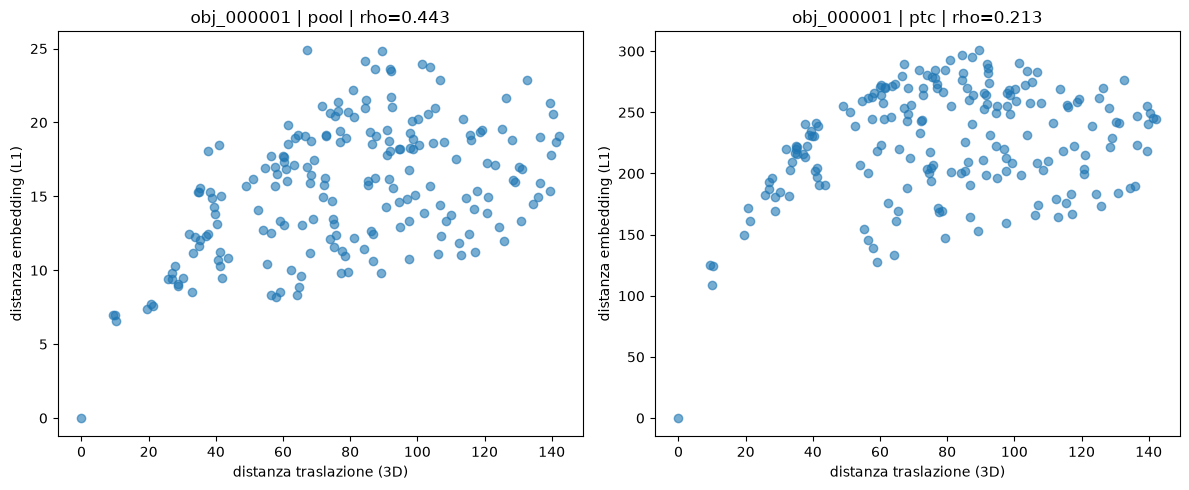

In [20]:
def scatter_trans_diag(obj_name, dataset="ycbv_translation", tokens=("pool", "ptc"),
                       component="all", ref_idx=0, grid=2):
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    T_all = df[["tx", "ty", "tz"]].values
    t_ref = T_all[ref_idx]
    img_paths = [str(RENDERS / p) for p in df["image"]]

    tdist = np.array([np.linalg.norm(T_all[i] - t_ref) if component == "all"
                      else None for i in range(len(df))])

    fig, axes = plt.subplots(1, len(tokens), figsize=(6*len(tokens), 5))
    if len(tokens) == 1: axes = [axes]

    clear_forward_cache()
    for ax, token in zip(axes, tokens):
        kwargs = {"grid": grid} if token in ("pool", "cubist") else {}
        e_ref = extract_features2(img_paths[ref_idx], token=token, **kwargs)
        dists = [torch.abs(e_ref - extract_features2(p, token=token, **kwargs)).sum().item()
                for p in img_paths]
        rho, _ = spearmanr(tdist, dists)
        ax.scatter(tdist, dists, alpha=0.6)
        ax.set_title(f"{obj_name} | {token} | rho={rho:.3f}")
        ax.set_xlabel("distanza traslazione (3D)")
        ax.set_ylabel("distanza embedding (L1)")
    plt.tight_layout()
    plt.show()

scatter_trans_diag("obj_000001")   # cambia oggetto per controllarne altri

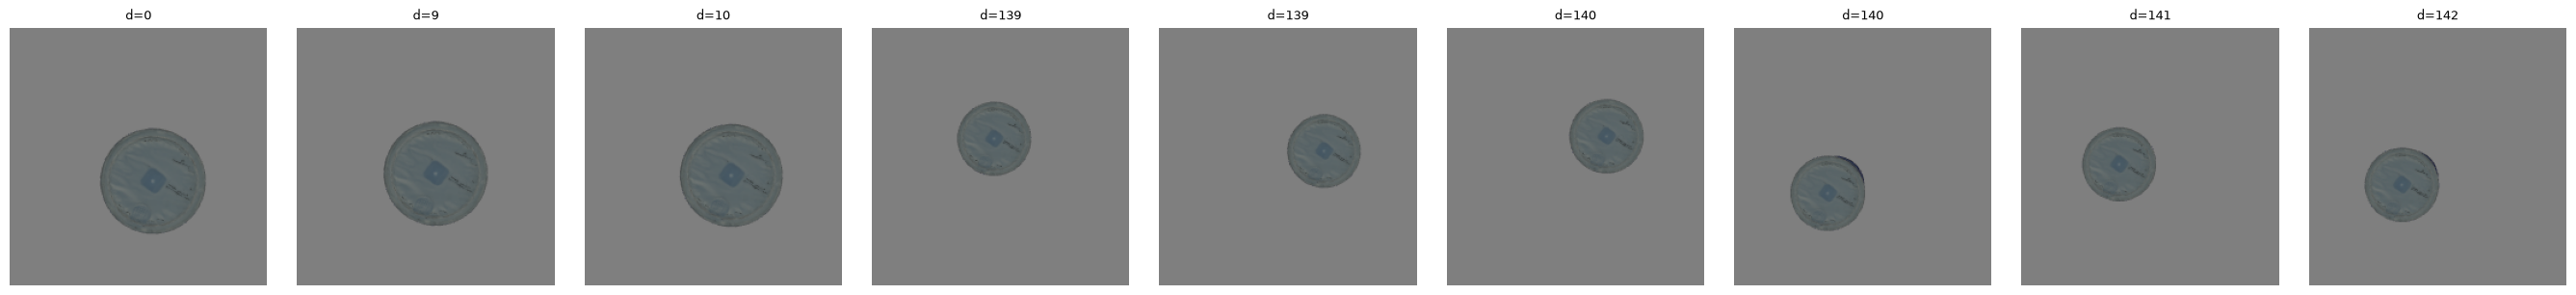

In [21]:
def show_translation_extremes(obj_name, dataset="ycbv_translation", ref_idx=0, n=6):
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    T_all = df[["tx", "ty", "tz"]].values
    t_ref = T_all[ref_idx]
    tdist = np.linalg.norm(T_all - t_ref, axis=1)

    order = np.argsort(tdist)
    idx_show = list(order[:3]) + list(order[-n:])  # 3 più vicine + n più lontane

    fig, axes = plt.subplots(1, len(idx_show), figsize=(3*len(idx_show), 3))
    for ax, i in zip(axes, idx_show):
        img = Image.open(RENDERS / df.loc[i, "image"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"d={tdist[i]:.0f}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_translation_extremes("obj_000001")

In [22]:
def translation_sensitivity_rho_persp(obj_name, dataset="ycbv_translation", token="pool",
                                       metric="L1", scale="inv_z", grid=2, layers=[-1],
                                       ref_idx=0, reduced_dim=32, use_cache=True):
    """Come translation_sensitivity_rho, ma con scala prospettica invece di distanza lineare.
       scale: "inv_z" (1/tz, proporzionale alla dimensione apparente), "log_z" (log tz),
              o "all" (comportamento originale, distanza euclidea 3D)."""
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    if len(df) < 5:
        return np.nan

    T_all = df[["tx", "ty", "tz"]].values
    t_ref = T_all[ref_idx]

    ref_path = str(RENDERS / df.loc[ref_idx, "image"])
    e_ref = extract_features2(ref_path, layers=layers, token=token, grid=grid,
                              reduced_dim=reduced_dim, use_cache=use_cache)

    xvals, dists = [], []
    for i in range(len(df)):
        if scale == "inv_z":
            x = abs(1.0/T_all[i, 2] - 1.0/t_ref[2])
        elif scale == "log_z":
            x = abs(np.log(T_all[i, 2]) - np.log(t_ref[2]))
        else:
            x = np.linalg.norm(T_all[i] - t_ref)

        img_path = str(RENDERS / df.loc[i, "image"])
        e = extract_features2(img_path, layers=layers, token=token, grid=grid,
                              reduced_dim=reduced_dim, use_cache=use_cache)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d); xvals.append(x)

    rho, _ = spearmanr(np.array(xvals), np.array(dists))
    return rho

In [ ]:
from itertools import product
import time

DATASET_T = "ycbv_translation"
METRIC_T = "L1"
GRID_T = 2
LAYERS_T = [-1]
REDUCED_DIM_T = 32

TOKENS_TO_COMPARE_TRANS = ["pool", "proj", "ptc", "cubist"]
SCALES_TO_COMPARE = ["all", "inv_z"]   # aggiungi "log_z" se vuoi anche quella

all_objs_trans_df = pd.read_csv(RENDERS / DATASET_T / "gt_poses.csv")
ALL_OBJECTS_TRANS = sorted(all_objs_trans_df["object"].unique())
print(f"{len(ALL_OBJECTS_TRANS)} oggetti trovati in {DATASET_T}: {ALL_OBJECTS_TRANS}")

records_persp = []
t0 = time.time()
for obj in ALL_OBJECTS_TRANS:
    clear_forward_cache()
    for token, scale in product(TOKENS_TO_COMPARE_TRANS, SCALES_TO_COMPARE):
        rho = translation_sensitivity_rho_persp(obj, dataset=DATASET_T, token=token,
                                                 metric=METRIC_T, scale=scale,
                                                 grid=GRID_T, layers=LAYERS_T,
                                                 reduced_dim=REDUCED_DIM_T)
        records_persp.append({"object": obj, "token": token, "scale": scale, "rho": rho})
        print(f"{obj:15s} | {token:6s} | scale={scale:6s} | rho = {rho:.3f}")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"\nCompletato in {time.time()-t0:.1f}s")
results_persp_df = pd.DataFrame(records_persp)

21 oggetti trovati in ycbv_translation: ['obj_000001', 'obj_000002', 'obj_000003', 'obj_000004', 'obj_000005', 'obj_000006', 'obj_000007', 'obj_000008', 'obj_000009', 'obj_000010', 'obj_000011', 'obj_000012', 'obj_000013', 'obj_000014', 'obj_000015', 'obj_000016', 'obj_000017', 'obj_000018', 'obj_000019', 'obj_000020', 'obj_000021']
obj_000001      | pool   | scale=all    | rho = 0.443
obj_000001      | pool   | scale=inv_z  | rho = 0.024
obj_000001      | proj   | scale=all    | rho = 0.207
obj_000001      | proj   | scale=inv_z  | rho = -0.217
obj_000001      | ptc    | scale=all    | rho = 0.213
obj_000001      | ptc    | scale=inv_z  | rho = -0.211
obj_000001      | cubist | scale=all    | rho = -0.131


In [ ]:
print("--- Media rho per token e scala ---")
summary_persp = results_persp_df.groupby(["token", "scale"])["rho"].agg(
    ["mean", "std", "count"]).reset_index()
print(summary_persp.to_string(index=False))

print("\n--- Test appaiato (Wilcoxon): 'all' vs 'inv_z', stesso oggetto+token ---")
for token in TOKENS_TO_COMPARE_TRANS:
    sub = results_persp_df[results_persp_df["token"] == token]
    pivot = sub.pivot(index="object", columns="scale", values="rho").dropna()
    if "all" in pivot.columns and "inv_z" in pivot.columns:
        stat, p = wilcoxon(pivot["all"], pivot["inv_z"])
        diff = (pivot["inv_z"] - pivot["all"]).mean()
        print(f"{token:8s} | inv_z - all = {diff:+.4f} | p-value = {p:.4f} | n={len(pivot)}"
              + ("  <-- significativo (p<0.05)" if p < 0.05 else ""))